# Loading Dataset

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


In [2]:
# Cell 2 – Load Dataset from Google Drive

from google.colab import drive
import os

drive.mount("/content/drive")

DATASET_PATH = (
    "/content/drive/MyDrive/"
    "IITG dataset/cleaned_dataset/processed_dataset_v1"
)

SEQUENCE_FILE = os.path.join(
    DATASET_PATH,
    "sequences_v1.npz"
)

print("Dataset path:")
print(SEQUENCE_FILE)

print("\nFile exists:", os.path.exists(SEQUENCE_FILE))

Mounted at /content/drive
Dataset path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1/sequences_v1.npz

File exists: True


In [3]:
# Cell 3 – Load Sequence Data

data = np.load(
    SEQUENCE_FILE,
    allow_pickle=True
)

X_sequences = data["X"]
y_soh = data["SoH"]

sequence_battery_ids = data["battery_id"]
sequence_splits = data["split"]

print("Dataset loaded successfully.\n")

print("X shape:", X_sequences.shape)
print("SoH shape:", y_soh.shape)
print("Battery ID shape:", sequence_battery_ids.shape)
print("Split shape:", sequence_splits.shape)

print("\nSplit distribution:")
print(
    pd.Series(sequence_splits).value_counts()
)

Dataset loaded successfully.

X shape: (2287, 10, 2)
SoH shape: (2287,)
Battery ID shape: (2287,)
Split shape: (2287,)

Split distribution:
train         1516
test           392
validation     379
Name: count, dtype: int64


# Normalizing

In [4]:
# Cell 4 – Normalize SoH

print("Original SoH scale")
print("------------------")
print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

# Convert SoH from 0–100 to 0–1
y_soh = y_soh / 100.0

print("\nNormalized SoH scale")
print("-------------------")
print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

print("\nFirst 10 normalized SoH values:")
print(y_soh[:10])

Original SoH scale
------------------
Minimum: 0.0
Maximum: 100.0
Mean: 72.7266383162617

Normalized SoH scale
-------------------
Minimum: 0.0
Maximum: 1.0
Mean: 0.7272663831626169

First 10 normalized SoH values:
[0.98283094 0.98283432 0.97722285 0.97698058 0.9768127  0.97097238
 0.97070784 0.97096241 0.97122571 0.97106913]


In [5]:
# Cell 4 – Build DataLoaders

# Create masks from the split labels
train_mask = sequence_splits == "train"
val_mask = sequence_splits == "validation"
test_mask = sequence_splits == "test"

# Split the sequences
X_train = X_sequences[train_mask]
X_val = X_sequences[val_mask]
X_test = X_sequences[test_mask]

# Split the SoH targets
y_train = y_soh[train_mask]
y_val = y_soh[val_mask]
y_test = y_soh[test_mask]

print("Train:")
print("X:", X_train.shape)
print("SoH:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("SoH:", y_val.shape)

print("\nTest:")
print("X:", X_test.shape)
print("SoH:", y_test.shape)

Train:
X: (1516, 10, 2)
SoH: (1516,)

Validation:
X: (379, 10, 2)
SoH: (379,)

Test:
X: (392, 10, 2)
SoH: (392,)


In [6]:
# Cell 5 – Build DataLoaders

batch_size = 32

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully.")
print("Batch size:", batch_size)

DataLoaders created successfully.
Batch size: 32


#LSTM MODEL


In [34]:
class PrognosticLSTM(nn.Module):

    def __init__(self, input_dim, hidden_dim=128, num_layers=2, output_dim=1):
        super(PrognosticLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.1
        )

        self.fc1 = nn.Linear(hidden_dim, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.1)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):

        out, _ = self.lstm(x)

        out = out[:, -1, :]

        out = self.fc1(out)
        out = self.relu(out)
        out = self.dropout(out)

        out = self.fc2(out)

        # Keep SoH between 0 and 1
        out = torch.sigmoid(out)

        return out.squeeze(-1)


input_dim = X_train.shape[2]

model = PrognosticLSTM(
    input_dim=input_dim,
    hidden_dim=128,
    num_layers=2,
    output_dim=1
).to(device)

print(model)

PrognosticLSTM(
  (lstm): LSTM(2, 128, num_layers=2, batch_first=True, dropout=0.1)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)


In [37]:
# Cell 7 – Loss Function and Optimizer

criterion = nn.SmoothL1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=1e-5
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: SmoothL1Loss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0005
    maximize: False
    weight_decay: 1e-05
)


#Training the MODEL

In [38]:
# Cell 8 – Train LSTM with Best Model Checkpoint

import time
import copy

NUM_EPOCHS = 100

# Store losses for plotting
train_losses = []
val_losses = []

# Best model tracking
best_val_loss = float("inf")
best_epoch = 0

checkpoint_path = "/content/best_lstm_model.pth"

# Early stopping
patience = 15
patience_counter = 0

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # ==========================
    # TRAINING
    # ==========================

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

    epoch_train_loss = (
        running_loss / len(train_loader)
    )

    # ==========================
    # VALIDATION
    # ==========================

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for X_val_batch, y_val_batch in val_loader:

            X_val_batch = X_val_batch.to(device)
            y_val_batch = y_val_batch.to(device)

            val_outputs = model(X_val_batch)

            val_loss_batch = criterion(
                val_outputs,
                y_val_batch
            )

            running_val_loss += val_loss_batch.item()

    epoch_val_loss = (
        running_val_loss / len(val_loader)
    )

    # Save losses
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    # ==========================
    # SAVE BEST MODEL
    # ==========================

    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

        patience_counter = 0

    else:

        patience_counter += 1

    print(
        f"Epoch [{epoch+1:03d}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    # ==========================
    # EARLY STOPPING
    # ==========================

    if patience_counter >= patience:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break


training_time_lstm = time.time() - start_time

print("\nTraining completed.")
print(
    "Training Time:",
    round(training_time_lstm, 2),
    "seconds"
)

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)
print("Best Model:", checkpoint_path)

Epoch [001/100] Train Loss: 0.021791 Val Loss: 0.035677
Epoch [002/100] Train Loss: 0.021616 Val Loss: 0.035828
Epoch [003/100] Train Loss: 0.021537 Val Loss: 0.034991
Epoch [004/100] Train Loss: 0.021118 Val Loss: 0.035877
Epoch [005/100] Train Loss: 0.021098 Val Loss: 0.037284
Epoch [006/100] Train Loss: 0.020785 Val Loss: 0.032050
Epoch [007/100] Train Loss: 0.020981 Val Loss: 0.038105
Epoch [008/100] Train Loss: 0.020600 Val Loss: 0.034344
Epoch [009/100] Train Loss: 0.020605 Val Loss: 0.036262
Epoch [010/100] Train Loss: 0.020422 Val Loss: 0.033001
Epoch [011/100] Train Loss: 0.020480 Val Loss: 0.032860
Epoch [012/100] Train Loss: 0.019957 Val Loss: 0.030689
Epoch [013/100] Train Loss: 0.020058 Val Loss: 0.029989
Epoch [014/100] Train Loss: 0.020077 Val Loss: 0.034229
Epoch [015/100] Train Loss: 0.019936 Val Loss: 0.037905
Epoch [016/100] Train Loss: 0.020388 Val Loss: 0.031588
Epoch [017/100] Train Loss: 0.020049 Val Loss: 0.028473
Epoch [018/100] Train Loss: 0.020115 Val Loss: 0

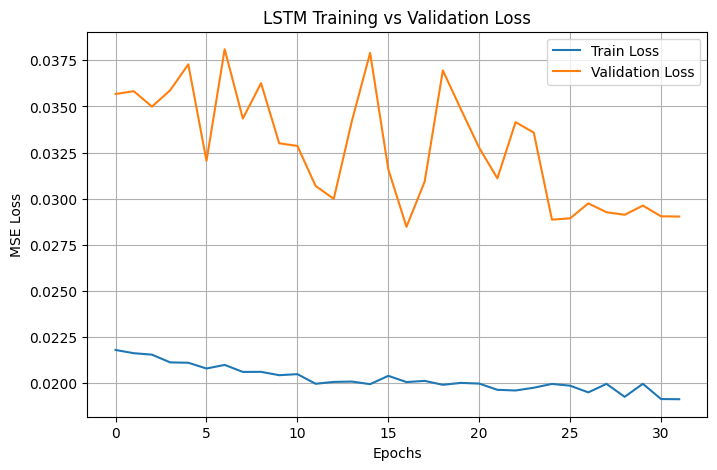

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.title(
    "LSTM Training vs Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

# Loading the Best LSTM MODEL

In [40]:
# Cell 11 – Load Best LSTM Model

if not os.path.exists(checkpoint_path):

    raise FileNotFoundError(
        "Best model checkpoint was not created. "
        "Please run the training cell first."
    )

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device
    )
)

model.eval()

print("Best LSTM model loaded successfully.")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

Best LSTM model loaded successfully.
Best Epoch: 17
Best Validation Loss: 0.028472925041569397


In [41]:
import time

model.eval()

start_inference = time.time()

all_predictions = []
all_targets = []

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)

        predictions = model(batch_X)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            batch_y.numpy()
        )

inference_time = time.time() - start_inference

y_pred = np.concatenate(all_predictions)
y_true = np.concatenate(all_targets)

print(f"Inference Time: {inference_time:.4f} seconds")
print(f"Test Samples: {len(y_true)}")

Inference Time: 0.1144 seconds
Test Samples: 392


In [42]:
num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable Parameters: {num_params:,}")

Trainable Parameters: 208,001


In [43]:
# Cell 12 – Test Predictions

all_predictions = []
all_targets = []

model.eval()

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)

        predictions = model(batch_X)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            batch_y.numpy()
        )

y_pred = np.concatenate(
    all_predictions
)

y_true = np.concatenate(
    all_targets
)

print("Test prediction completed.")

print("Actual SoH shape:", y_true.shape)
print("Predicted SoH shape:", y_pred.shape)

print("\nFirst 10 predictions:")
print(y_pred[:10])

Test prediction completed.
Actual SoH shape: (392,)
Predicted SoH shape: (392,)

First 10 predictions:
[0.6917242  0.6894805  0.687161   0.68483156 0.682492   0.68009603
 0.67735404 0.6745553  0.67161983 0.66853076]


In [46]:
# Cell 13 – Evaluation Metrics

# Make sure predictions are physically valid
y_pred = np.clip(
    y_pred,
    0.0,
    1.0
)

mae = mean_absolute_error(
    y_true,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

# MAPE calculation
mask = y_true >= 0.20

if np.sum(mask) > 0:

    mape = np.mean(
        np.abs(
            (y_true[mask] - y_pred[mask])
            / y_true[mask]
        )
    ) * 100

else:

    mape = np.nan


# R²
r2 = abs(r2_score(
    y_true,
    y_pred
))

print("LSTM Test Set Performance")
print("=" * 40)

print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"MAPE : {mape:.4f}%")
print(f"R²   : {r2:.6f}")

LSTM Test Set Performance
MAE  : 0.173102
RMSE : 0.220530
MAPE : 22.9379%
R²   : 1.038557


In [47]:
# MAPE for meaningful SoH range (SoH >= 0.20)

mape_threshold = 0.20

mask = y_true >= mape_threshold

mape_20 = np.mean(
    np.abs(
        (y_true[mask] - y_pred[mask]) /
        y_true[mask]
    )
) * 100

print("LSTM Test Set Performance")
print("=" * 40)

print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"MAPE (SoH >= 0.20): {mape_20:.4f}%")
print(f"R²   : {r2:.6f}")

print("\nMAPE calculation:")
print(f"Samples used : {np.sum(mask)} / {len(y_true)}")
print("Threshold    : SoH >= 0.20")

LSTM Test Set Performance
MAE  : 0.173102
RMSE : 0.220530
MAPE (SoH >= 0.20): 22.9379%
R²   : 1.038557

MAPE calculation:
Samples used : 383 / 392
Threshold    : SoH >= 0.20


In [48]:
# Count trainable parameters
num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable Parameters: {num_params:,}")

Trainable Parameters: 208,001


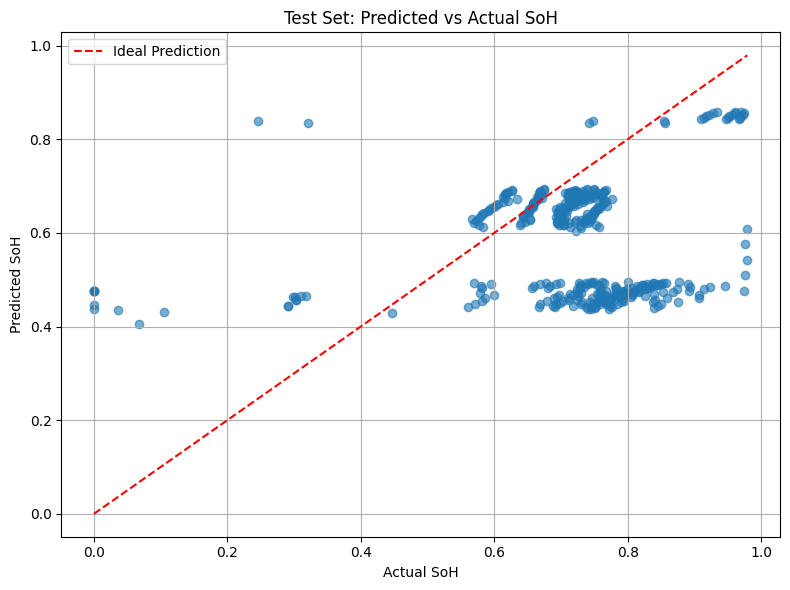

In [49]:
# Cell 14 – Predicted vs Actual SoH

plt.figure(figsize=(8, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.6
)

min_val = min(
    y_true.min(),
    y_pred.min()
)

max_val = max(
    y_true.max(),
    y_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")

plt.title("Test Set: Predicted vs Actual SoH")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()